In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import math

In [28]:
df = pd.read_csv(r'..\..\data\raw\hr_employee_attrition.csv')
display(df)

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1465,36,No,Travel_Frequently,884,Research & Development,23,2,Medical,1,2061,...,3,80,1,17,3,3,5,2,0,3
1466,39,No,Travel_Rarely,613,Research & Development,6,1,Medical,1,2062,...,1,80,1,9,5,3,7,7,1,7
1467,27,No,Travel_Rarely,155,Research & Development,4,3,Life Sciences,1,2064,...,2,80,1,6,0,3,6,2,0,3
1468,49,No,Travel_Frequently,1023,Sales,2,3,Medical,1,2065,...,4,80,0,17,3,2,9,6,0,8


In [29]:
df.info(memory_usage='deep')

<class 'pandas.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   Age                       1470 non-null   int64
 1   Attrition                 1470 non-null   str  
 2   BusinessTravel            1470 non-null   str  
 3   DailyRate                 1470 non-null   int64
 4   Department                1470 non-null   str  
 5   DistanceFromHome          1470 non-null   int64
 6   Education                 1470 non-null   int64
 7   EducationField            1470 non-null   str  
 8   EmployeeCount             1470 non-null   int64
 9   EmployeeNumber            1470 non-null   int64
 10  EnvironmentSatisfaction   1470 non-null   int64
 11  Gender                    1470 non-null   str  
 12  HourlyRate                1470 non-null   int64
 13  JobInvolvement            1470 non-null   int64
 14  JobLevel                  1470 non-null   int64
 15

In [30]:
display(df.nunique())

Age                           43
Attrition                      2
BusinessTravel                 3
DailyRate                    886
Department                     3
DistanceFromHome              29
Education                      5
EducationField                 6
EmployeeCount                  1
EmployeeNumber              1470
EnvironmentSatisfaction        4
Gender                         2
HourlyRate                    71
JobInvolvement                 4
JobLevel                       5
JobRole                        9
JobSatisfaction                4
MaritalStatus                  3
MonthlyIncome               1349
MonthlyRate                 1427
NumCompaniesWorked            10
Over18                         1
OverTime                       2
PercentSalaryHike             15
PerformanceRating              2
RelationshipSatisfaction       4
StandardHours                  1
StockOptionLevel               4
TotalWorkingYears             40
TrainingTimesLastYear          7
WorkLifeBa

In [31]:
df.drop(columns=['EmployeeCount','EmployeeNumber','Over18','StandardHours']);

In [32]:
print(df.duplicated().sum())

0


In [33]:
ordered_columns = [
    # Personal
    'Age', 'Gender', 'MaritalStatus', 'Education', 'EducationField', 'DistanceFromHome',

    # Job Context
    'Department', 'JobRole', 'JobLevel', 'BusinessTravel', 'OverTime',

    # Financial
    'MonthlyIncome', 'DailyRate', 'HourlyRate', 'MonthlyRate', 'PercentSalaryHike', 'StockOptionLevel',

    # Work Experience & Tenure
    'TotalWorkingYears', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager', 'NumCompaniesWorked',

    # Performance & Satisfaction
    'EnvironmentSatisfaction', 'JobSatisfaction', 'RelationshipSatisfaction', 'WorkLifeBalance', 'JobInvolvement', 'PerformanceRating', 'TrainingTimesLastYear',

     # Target
    'Attrition'
]

df = df[ordered_columns]
display(df)

,Age,Gender,MaritalStatus,Education,EducationField,DistanceFromHome,Department,JobRole,JobLevel,BusinessTravel,...,YearsWithCurrManager,NumCompaniesWorked,EnvironmentSatisfaction,JobSatisfaction,RelationshipSatisfaction,WorkLifeBalance,JobInvolvement,PerformanceRating,TrainingTimesLastYear,Attrition
0,41,Female,Single,2,Life Sciences,1,Sales,Sales Executive,2,Travel_Rarely,...,5,8,2,4,1,1,3,3,0,Yes
1,49,Male,Married,1,Life Sciences,8,Research & Development,Research Scientist,2,Travel_Frequently,...,7,1,3,2,4,3,2,4,3,No
2,37,Male,Single,2,Other,2,Research & Development,Laboratory Technician,1,Travel_Rarely,...,0,6,4,3,2,3,2,3,3,Yes
3,33,Female,Married,4,Life Sciences,3,Research & Development,Research Scientist,1,Travel_Frequently,...,0,1,4,3,3,3,3,3,3,No
4,27,Male,Married,1,Medical,2,Research & Development,Laboratory Technician,1,Travel_Rarely,...,2,9,1,2,4,3,3,3,3,No
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1465,36,Male,Married,2,Medical,23,Research & Development,Laboratory Technician,2,Travel_Frequently,...,3,4,3,4,3,3,4,3,3,No
1466,39,Male,Married,1,Medical,6,Research & Development,Healthcare Representative,3,Travel_Rarely,...,7,4,4,1,1,3,2,3,5,No
1467,27,Male,Married,3,Life Sciences,4,Research & Development,Manufacturing Director,2,Travel_Rarely,...,3,1,2,2,2,3,4,4,0,No
1468,49,Male,Married,3,Medical,2,Sales,Sales Executive,2,Travel_Frequently,...,8,2,4,2,4,2,2,3,3,No


In [34]:
continuous_columns = [
    'Age', 'DistanceFromHome', 'MonthlyIncome', 'DailyRate', 'HourlyRate',
    'MonthlyRate', 'PercentSalaryHike', 'TotalWorkingYears', 'YearsAtCompany',
    'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager',
    'NumCompaniesWorked', 'TrainingTimesLastYear'
]

categorical_columns = [
    'Gender', 'MaritalStatus', 'Education', 'EducationField', 'Department',
    'JobRole', 'JobLevel', 'BusinessTravel', 'OverTime', 'StockOptionLevel',
    'EnvironmentSatisfaction', 'JobSatisfaction', 'RelationshipSatisfaction',
    'WorkLifeBalance', 'JobInvolvement', 'PerformanceRating', 'Attrition'
]

In [35]:
display(df[continuous_columns].describe().T)

,count,mean,std,min,25%,50%,75%,max
Age,1470.0,36.923810,9.135373,18.0,30.0,36.0,43.00,60.0
DistanceFromHome,1470.0,9.192517,8.106864,1.0,2.0,7.0,14.00,29.0
MonthlyIncome,1470.0,6502.931293,4707.956783,1009.0,2911.0,4919.0,8379.00,19999.0
DailyRate,1470.0,802.485714,403.509100,102.0,465.0,802.0,1157.00,1499.0
HourlyRate,1470.0,65.891156,20.329428,30.0,48.0,66.0,83.75,100.0
MonthlyRate,1470.0,14313.103401,7117.786044,2094.0,8047.0,14235.5,20461.50,26999.0
PercentSalaryHike,1470.0,15.209524,3.659938,11.0,12.0,14.0,18.00,25.0
TotalWorkingYears,1470.0,11.279592,7.780782,0.0,6.0,10.0,15.00,40.0
YearsAtCompany,1470.0,7.008163,6.126525,0.0,3.0,5.0,9.00,40.0
YearsInCurrentRole,1470.0,4.229252,3.623137,0.0,2.0,3.0,7.00,18.0


In [36]:
outlier_summary = {}

for column in continuous_columns:
    q1 = df[column].quantile(0.25)
    q3 = df[column].quantile(0.75)
    iqr = q3 - q1

    lower_limit = q1 - 1.5 * iqr
    upper_limit = q3 + 1.5 * iqr

    outliers_count = (~df[column].between(lower_limit, upper_limit)).sum()
    if outliers_count > 0:
        outlier_summary[column] = (lower_limit,upper_limit)
        print(f'{column:25s} -> {outliers_count}')


MonthlyIncome             -> 114
TotalWorkingYears         -> 63
YearsAtCompany            -> 104
YearsInCurrentRole        -> 21
YearsSinceLastPromotion   -> 107
YearsWithCurrManager      -> 14
NumCompaniesWorked        -> 52
TrainingTimesLastYear     -> 238


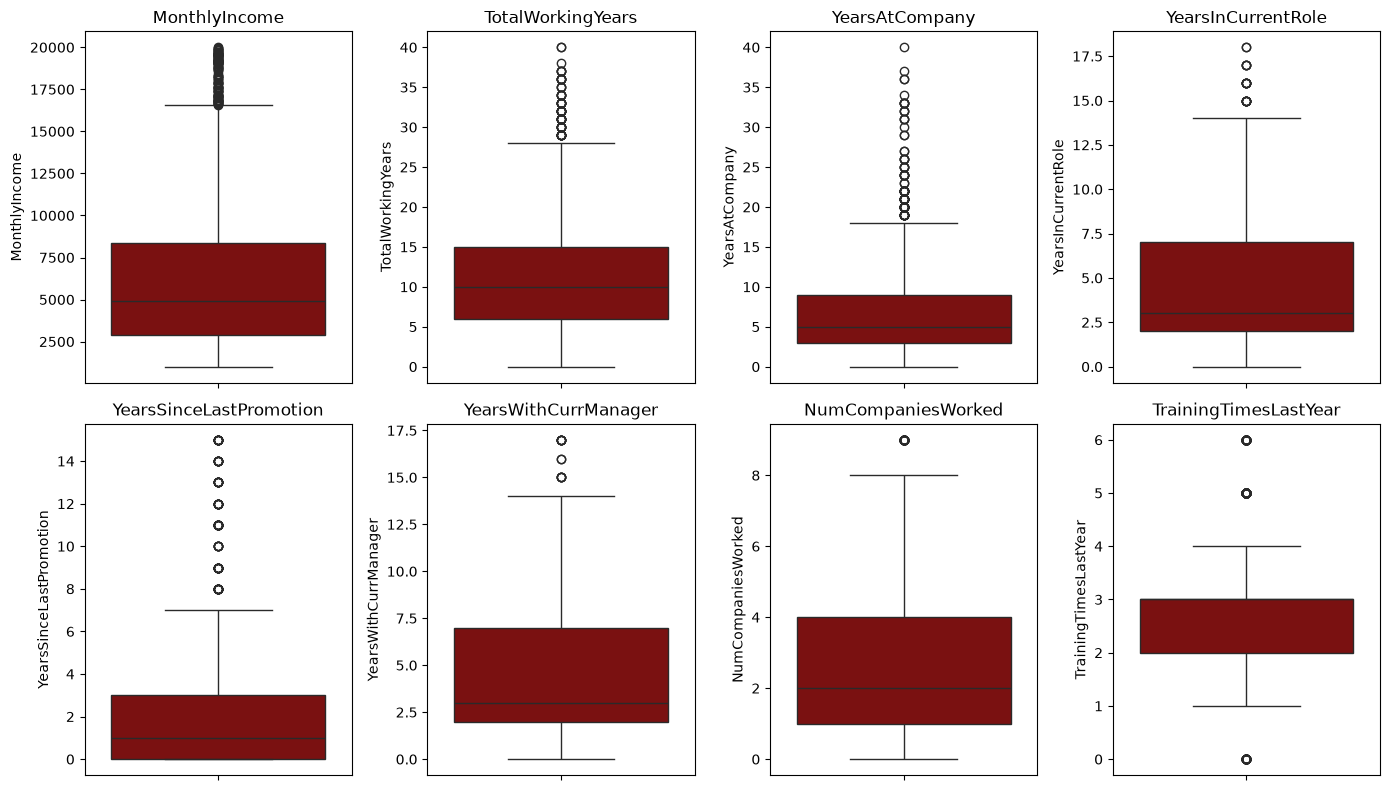

In [37]:
columns = list(outlier_summary.keys())
n_columns = 4
n_rows = math.ceil(len(columns) / n_columns)

figure, axes = plt.subplots(n_rows, n_columns, figsize=(14, 4 * n_rows))

if len(columns) == 1:
    axes = [axes]
else:
    axes = axes.flatten()

for i, column in enumerate(columns):
    sns.boxplot(data=df, y=column, ax=axes[i], color='darkred')
    axes[i].set_title(column)

for j in range(len(columns), len(axes)):
    figure.delaxes(axes[j])

plt.tight_layout()
plt.show()

In [38]:
for column,bounds in outlier_summary.items():
    df[column] = df[column].clip(bounds[0], bounds[1])

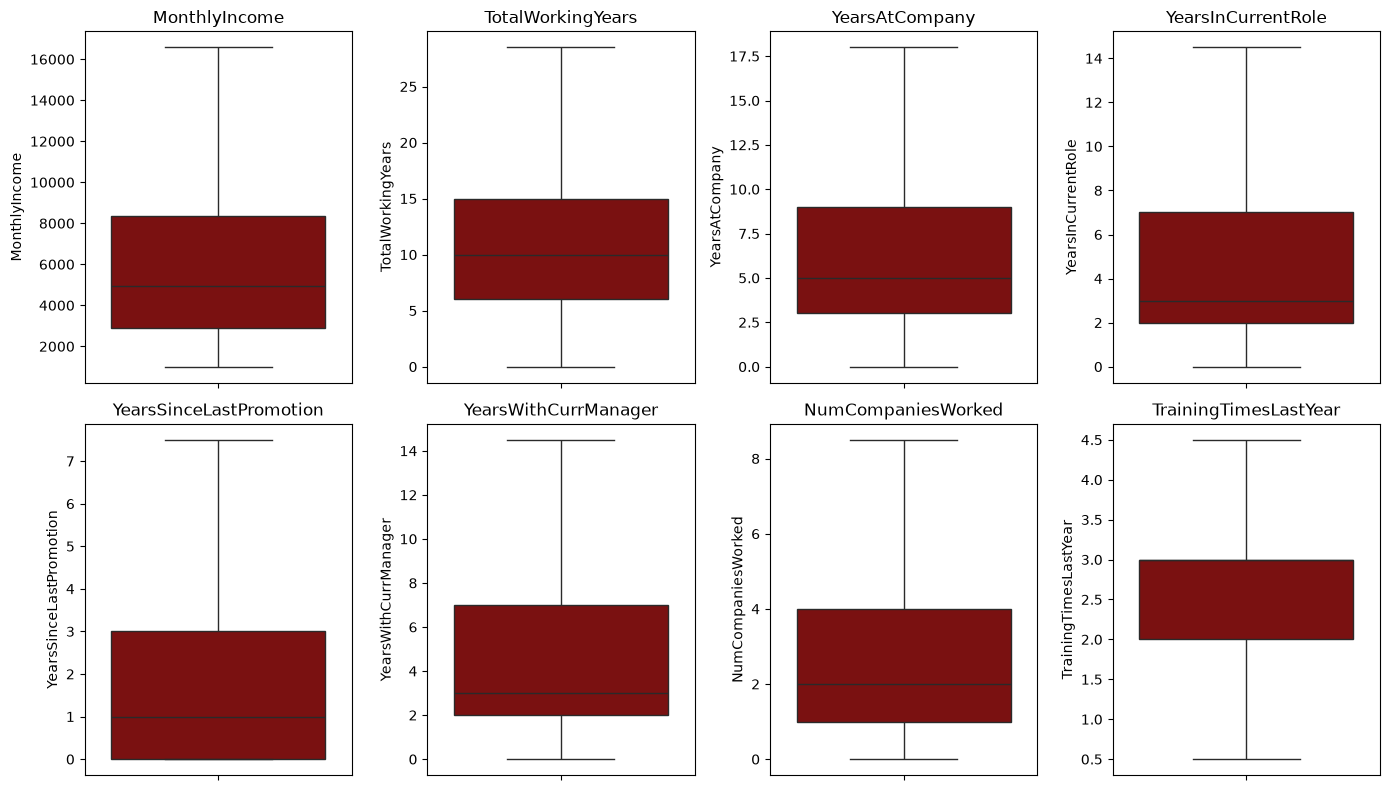

In [39]:
columns = list(outlier_summary.keys())
n_columns = 4
n_rows = math.ceil(len(columns) / n_columns)

figure, axes = plt.subplots(n_rows, n_columns, figsize=(14, 4 * n_rows))

if len(columns) == 1:
    axes = [axes]
else:
    axes = axes.flatten()

for i, column in enumerate(columns):
    sns.boxplot(data=df, y=column, ax=axes[i], color='darkred')
    axes[i].set_title(column)

for j in range(len(columns), len(axes)):
    figure.delaxes(axes[j])

plt.tight_layout()
plt.show()

In [40]:
skewed_columns = []

for column in continuous_columns:
    skewness = df[column].skew()

    if abs(skewness) > 1:
        skewed_columns.append(column)
        print(f'{column:25s} -> {skewness}')

MonthlyIncome             -> 1.1685950659135085
YearsSinceLastPromotion   -> 1.2625629837973027


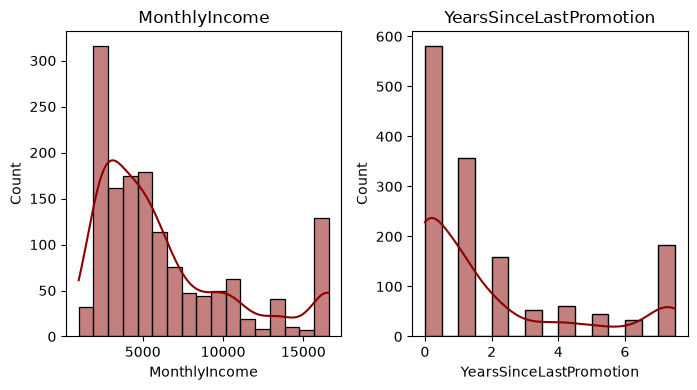

In [41]:
columns = skewed_columns
n_columns = 4
n_rows = math.ceil(len(columns) / n_columns)

figure, axes = plt.subplots(n_rows, n_columns, figsize=(14, 4 * n_rows))

if len(columns) == 1:
    axes = [axes]
else:
    axes = axes.flatten()

for i, column in enumerate(columns):
    sns.histplot(df,x=column,ax=axes[i],color='darkred',kde=True)
    axes[i].set_title(column)

for j in range(len(columns), len(axes)):
    figure.delaxes(axes[j])

plt.tight_layout()
plt.show()

In [42]:
df['MonthlyIncome'] = np.log(df['MonthlyIncome'])
df['YearsSinceLastPromotion'] = np.log1p(df['YearsSinceLastPromotion'])

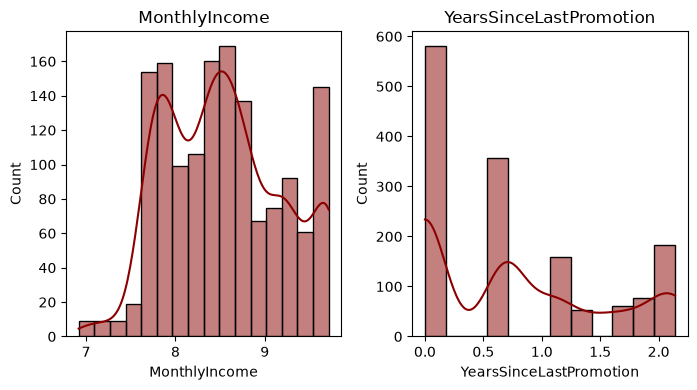

In [43]:
columns = skewed_columns
n_columns = 4
n_rows = math.ceil(len(columns) / n_columns)

figure, axes = plt.subplots(n_rows, n_columns, figsize=(14, 4 * n_rows))

if len(columns) == 1:
    axes = [axes]
else:
    axes = axes.flatten()

for i, column in enumerate(columns):
    sns.histplot(df,x=column,ax=axes[i],color='darkred',kde=True)
    axes[i].set_title(column)

for j in range(len(columns), len(axes)):
    figure.delaxes(axes[j])

plt.tight_layout()
plt.show()

In [44]:
imbalanced_columns = []
threshold = 0.70

for column in categorical_columns:
    max_proportion = df[column].value_counts(normalize=True).iloc[0]

    if  max_proportion >= threshold:
        imbalanced_columns.append(column)
        print(f'{column:25s} -> {max_proportion}')

BusinessTravel            -> 0.7095238095238096
OverTime                  -> 0.7170068027210884
PerformanceRating         -> 0.8462585034013606
Attrition                 -> 0.8387755102040816


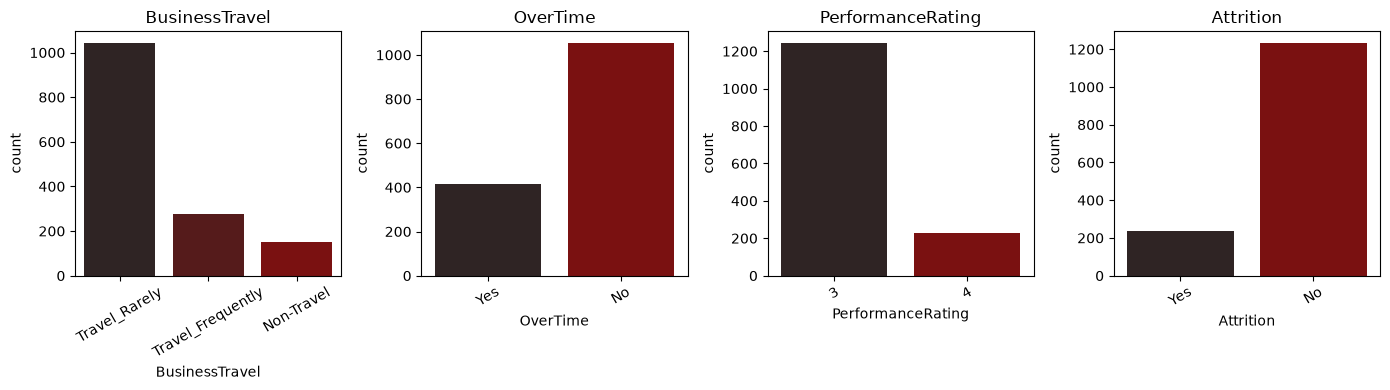

In [45]:
columns = imbalanced_columns
n_columns = 4
n_rows = math.ceil(len(columns) / n_columns)

figure, axes = plt.subplots(n_rows, n_columns, figsize=(14, 4 * n_rows))

if len(columns) == 1:
    axes = [axes]
else:
    axes = axes.flatten()

for i, column in enumerate(columns):
    sns.countplot(data=df, x=column, ax=axes[i],hue=column, palette='dark:darkred',legend=False)
    axes[i].set_title(column)
    axes[i].tick_params(axis='x', rotation= 30)

for j in range(len(columns), len(axes)):
    figure.delaxes(axes[j])

plt.tight_layout()
plt.show()

In [46]:
df['attrition_encoded'] = df['Attrition'].map({'No' : 0,'Yes': 1})

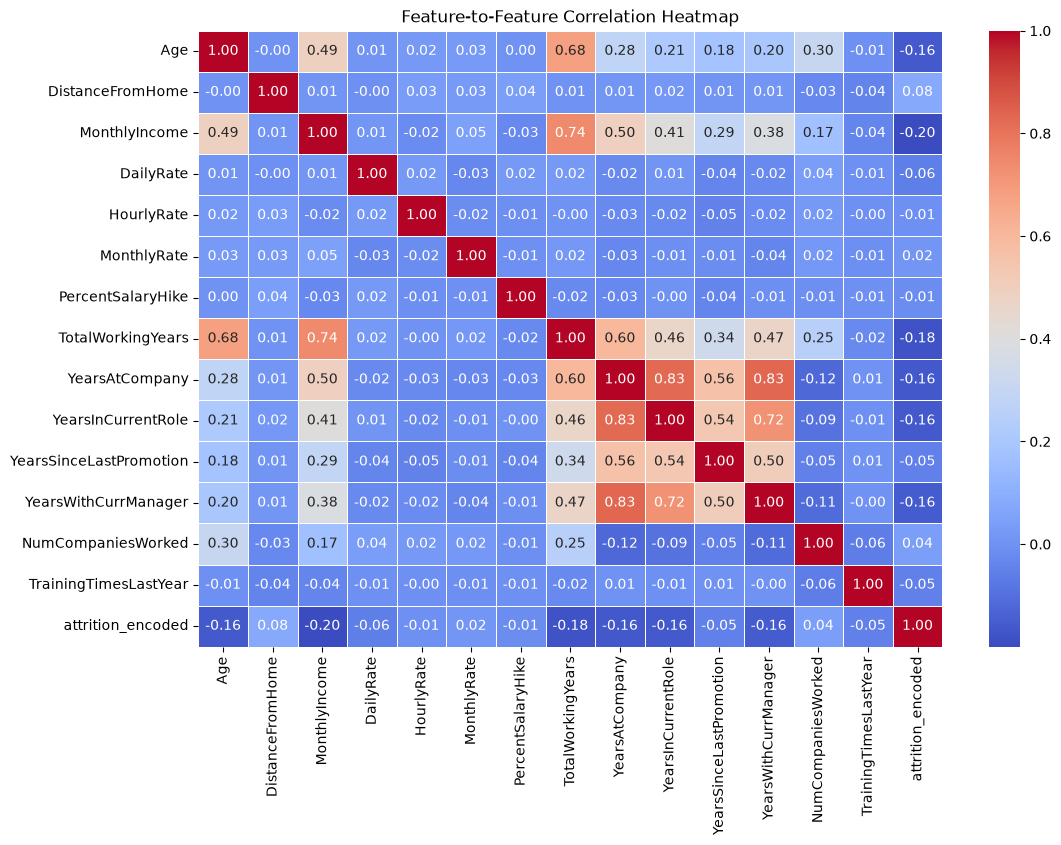

In [47]:
plt.figure(figsize=(12, 8))
sns.heatmap(df[[*continuous_columns,'attrition_encoded']].corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Feature-to-Feature Correlation Heatmap')
plt.show()

In [53]:
# Weak Corrleation With Label
# DailyRate, HourlyRate, MonthlyRate, PercentSalaryHike, YearsSinceLastPromotion, NumCompaniesWorked, TrainingtimesLastYear

# =========================================================
# Multicollinearity
# =========================================================
# TotalWorkingYears (-0.18) <-> Age (-0.16) => (0.68)
# TotalWorkingYears (-0.18) <-> MonthlyIncome (-0.20) => (0.74)
# TotalWorkingYears (-0.18) <-> YearsAtCompany (-0.16)  => (0.60)
# YearsWithCurrentManager (-0.16) <-> YearsAtCompany (-0.16) => (0.83)
# YearsInCurrentRole (-0.16) <-> YearsAtCompany (-0.16) => (0.83)
# YearsInCurrentRule (-0.16) <-> YearsWithCurrentManager (-0.16) => (0.72)

continuous_features = [
    'DistanceFromHome', 'MonthlyIncome', 'TotalWorkingYears', 'YearsAtCompany']

In [49]:
from scipy.stats import chi2_contingency

chi2_results = []

for column in categorical_columns:
    contingency_table = pd.crosstab(df[column], df['Attrition'])
    
    chi2, p, dof, expected = chi2_contingency(contingency_table)
    
    n = contingency_table.sum().sum()
    min_dim = min(contingency_table.shape) - 1
    cramers_v = np.sqrt(chi2 / (n * min_dim)) if min_dim > 0 else 0
    
    chi2_results.append({
        'Feature': column,
        'Chi2 Statistic': round(chi2, 4),
        'p-value': round(p, 5),
        'Significant (p < 0.05)': p < 0.05,
        "Cramér's V": round(cramers_v, 4)
       
    })

chi2_df = pd.DataFrame(chi2_results).sort_values(by="Cramér's V", ascending=False)
display(chi2_df)

,Feature,Chi2 Statistic,p-value,Significant (p < 0.05),Cramér's V
16,Attrition,1462.6146,0.00000,True,0.9975
8,OverTime,87.5643,0.00000,True,0.2441
5,JobRole,86.1903,0.00000,True,0.2421
6,JobLevel,72.5290,0.00000,True,0.2221
9,StockOptionLevel,60.5983,0.00000,True,0.2030
1,MaritalStatus,46.1637,0.00000,True,0.1772
14,JobInvolvement,28.4920,0.00000,True,0.1392
7,BusinessTravel,24.1824,0.00001,True,0.1283
10,EnvironmentSatisfaction,22.5039,0.00005,True,0.1237
11,JobSatisfaction,17.5051,0.00056,True,0.1091


In [52]:
categorical_features = [
    'MaritalStatus', 'EducationField', 'Department', 'JobRole', 'JobLevel', 'BusinessTravel', 'OverTime',
    'StockOptionLevel', 'EnvironmentSatisfaction', 'JobSatisfaction', 'WorkLifeBalance', 'JobInvolvement'
]

In [ ]:
X = df[continuous_features + categorical_features]
y = df['Attrition'].map({'No': 0, 'Yes': 1})

In [ ]:
from sklearn.model_selection import train_test_split

X_train,X_test,y_train,y_test= train_test_split(X,y,train_size=0.8,random_state=42,stratify=y)

In [63]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder,StandardScaler

preprocessor = ColumnTransformer(
    transformers = [
        ('cat',OneHotEncoder(drop='first',sparse_output=False),['MaritalStatus', 'EducationField', 'Department', 'JobRole', 'BusinessTravel', 'OverTime']),
        ('num',StandardScaler(),continuous_features + ['JobLevel','StockOptionLevel','EnvironmentSatisfaction','JobSatisfaction','WorkLifeBalance','JobInvolvement']),
    ]
)

X_train_preprocessed = preprocessor.fit_transform(X_train)
X_test_preprocessed = preprocessor.transform(X_test)